# 08 | Which edges and networks account for the coupling reversal?

**Learning goals:** distinguish shared from session-specific SC supports; reconstruct Spearman coupling from edge rank products; compare additive terms with reranked deletion; inspect atlas edges and conditional matched controls.

**Primary FC stability:** notebook 14 recommends 97 distinct frames per session from nonreplacement ten-frame blocks, with complete WM/CSF nuisance refitting. These equal-duration subset ranges are conditional stability summaries, not full-run confidence intervals. The observed full-run points remain unchanged. Notebooks 10/11/13 retain earlier bootstrap, matching and mechanism analyses as sensitivities. See `config/PRIMARY_FC_RESAMPLING.md`. **Current SC policy:** graphs, network means and simulations use each session's 16/20 consensus with mean counts per 10,000 attempted seeds. Primary paired coupling uses the 823-edge intersection with session-specific weights. See `config/PRIMARY_SC.md`. Historical seed-160 diagnostics in notebooks 07/08 remain sensitivity analyses; notebook 09 supplies the reliability evidence. Notebook 10 quantifies joint seed/FC sampling under this policy, including matched designs and support reselection. Notebook 11 extends the full-run branch to paired nuisance refits; notebook 12 integrates all clinical/context fields with network uncertainty. Notebook 13 diagnoses PCA-training shifts and compares nonreplacement blocks at matched distinct counts and 80% retention. The rule is post hoc and does not validate anatomy or a surgical/cognitive effect.

In [1]:
from pathlib import Path
import os, sys, json
root = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
os.environ.setdefault("MPLCONFIGDIR", str(root/".cache/matplotlib"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown, Image
from pat16 import ROOT, DATA, RESULTS, SESSIONS
from pat16.connectivity import labels
from pat16.primary_sc import load_weights
nodes = pd.read_csv(RESULTS/"nodes.csv")
summary = json.loads((RESULTS/"summary.json").read_text())
plt.rcParams.update({"figure.figsize": (9,4), "font.size": 10})


In [2]:
display(pd.read_csv(RESULTS/"primary_sc/network_contributions.csv"))
print("Current accounting sums to primary Δ=-0.04173, strict Δ=-0.03424, and their difference +0.00749. Historical accounting below concerns the original +0.03186 reversal shift.")

,network_pair,edges,primary_delta_term,strict_delta_term,reversal_shift_term
0,Cont / Cont,21,-0.000190,0.005874,0.006064
1,Cont / Default,69,-0.009921,-0.007163,0.002758
2,Cont / DorsAttn,45,0.000784,-0.007107,-0.007892
3,Cont / Limbic,9,-0.000586,0.001002,0.001588
4,Cont / SalVentAttn,33,-0.004086,0.002854,0.006940
5,Cont / SomMot,26,0.004243,0.008200,0.003957
6,Cont / Vis,13,0.005652,0.001365,-0.004287
7,Default / Default,60,-0.006110,-0.016584,-0.010474
8,Default / DorsAttn,50,-0.003962,-0.001314,0.002648
9,Default / Limbic,33,0.008487,0.010978,0.002490


Current accounting sums to primary Δ=-0.04173, strict Δ=-0.03424, and their difference +0.00749. Historical accounting below concerns the original +0.03186 reversal shift.


## Define what is being localized
Let Δ(a)=ρ(post,a)−ρ(pre,a). The primary Δ is −0.0207203 and strict Δ is +0.0111444. Here **R=Δ(strict)−Δ(primary)=+0.0318647** is the *sensitivity of a longitudinal statistic to censoring/refitting*, not a surgical effect. Notebook 07 investigates the sampling/refitting sequence; this notebook allocates that sensitivity to measured edge populations.

The SC union has **2003** undirected edges: **1071 shared, 444 pre-op-only and 488 post-op-only**. “Only” refers to this tractography reconstruction, not proven tract loss/gain. Edges absent from both supports are omitted. Coupling uses positive SC edges without graph-density thresholding. All inputs of this historical seed-160 analysis are preserved; current primary consensus results are shown above.

### An exact additive identity
Spearman coupling is Pearson correlation of average ranks (ties retain their average rank). For centered SC and FC ranks x,y in one session's **full nonzero-SC support**, define cₑ=xₑyₑ/√(Σx²Σy²). Then Σcₑ=ρ exactly. Counts and log1p(SC fractions) have the same ranks. On the union, an absent edge contributes zero *to accounting*; its FC is never zero-imputed or ranked.

Define rₑ=(c(post,strict)−c(pre,strict))−(c(post,primary)−c(pre,primary)). Sum rₑ by support or unordered network pair to recover R. These are global-rank bookkeeping terms, **not subgroup correlations, causal effects or independent-edge importance scores**. Ranks and normalizers change when the edge universe changes.

,edges,primary_delta_contribution,pca_delta_contribution,reversal_shift,preop_median_count,postop_median_count,preop_fraction_counts_le2,postop_fraction_counts_le2
support_group,,,,,,,,
shared,1071,-0.026557,-0.018227,0.008330,5.0,6.0,0.291317,0.282913
pre_only,444,-0.055396,-0.031024,0.024372,2.0,NaN,0.619369,NaN
post_only,488,0.061232,0.060395,-0.000837,NaN,2.0,NaN,0.663934


Sum of support R terms: 0.0318647118208369


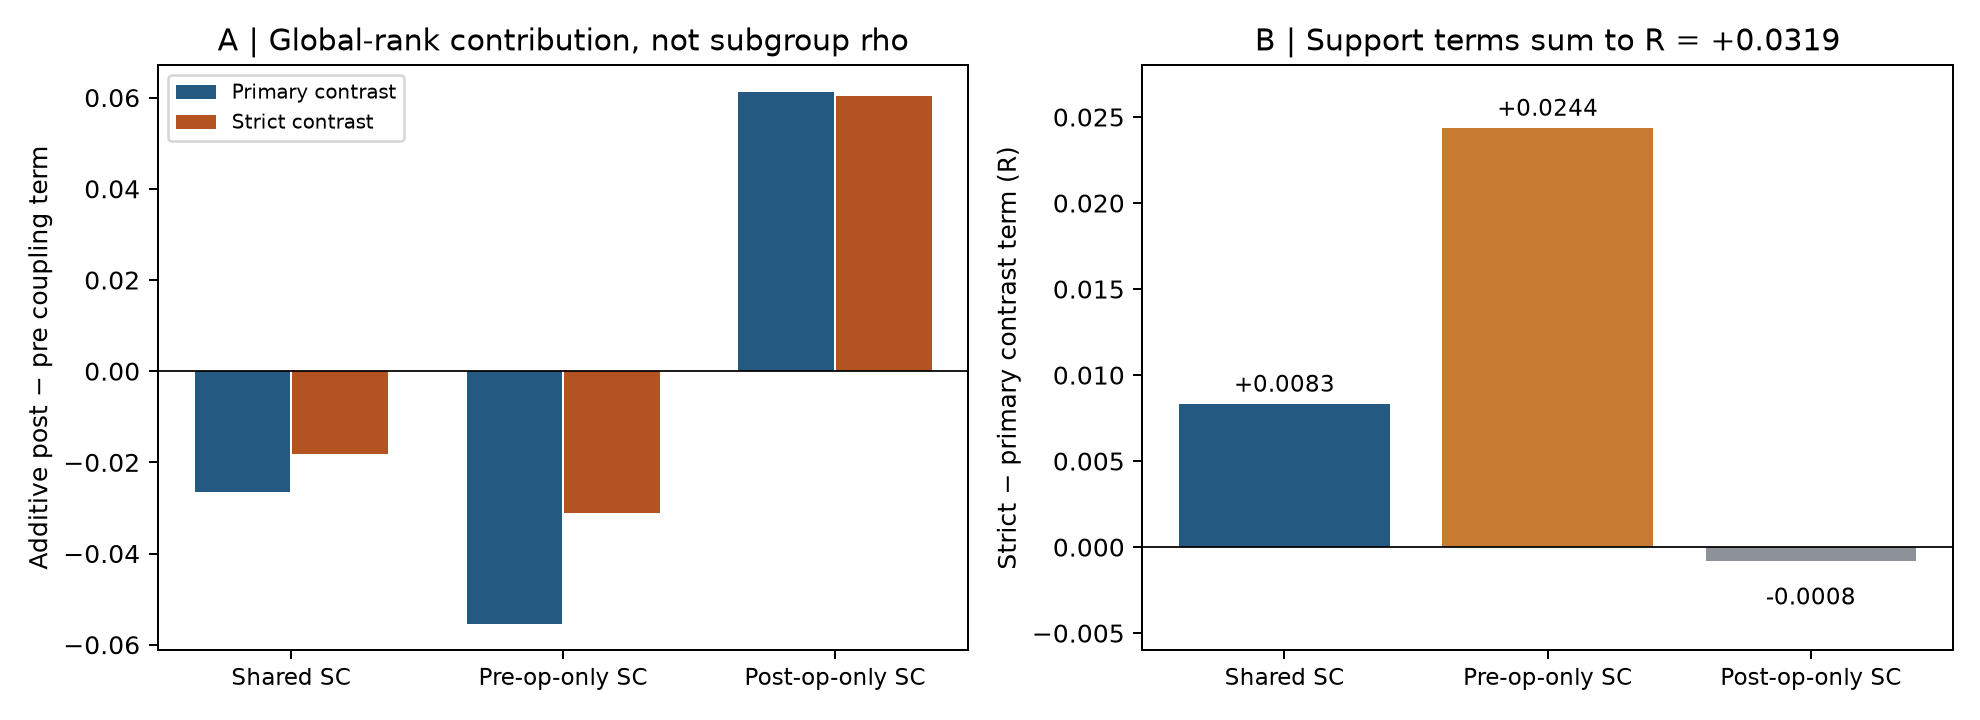

In [3]:
from pat16.edge_drivers import OUT, GROUPS, GROUP_LABELS, NETWORKS, show_edges
edges=pd.read_csv(OUT/"edges.csv")
support=pd.read_csv(OUT/"support_summary.csv").set_index("support_group").loc[GROUPS]
context=pd.read_csv(OUT/"rank_context.csv")
display(support[["edges","primary_delta_contribution","pca_delta_contribution","reversal_shift","preop_median_count","postop_median_count","preop_fraction_counts_le2","postop_fraction_counts_le2"]])
print("Sum of support R terms:",support.reversal_shift.sum())
display(Image(filename=str(RESULTS/"figures/edge_driver_support.png")))

## Shared and session-specific edges
Pre-op-only edges supply **+0.02437**, shared edges **+0.00833**, and post-op-only edges **−0.00084** to R. This is signed accounting with cancellation, not a fraction of biological variance explained. Pre-only/post-only median SC counts are 2; 61.9%/66.4% have only 1–2 streamlines, versus 29.1%/28.3% among shared edges. Low counts do not prove invalidity, but support labels depend on reconstruction and endpoint rules.

The pre-only pooled coupling contribution falls from +0.05540 to +0.03102 when strict denoising is used. Mean FC rises from 0.1046 to 0.1338 and mean **relative FC rank** rises from 0.4293 to 0.4543. These low-SC edges become less uniformly low-FC in the pooled ordering, shrinking the positive low-SC/low-FC association. Both within-group rank covariance and between-group rank-location terms change. This does not identify whether removed covariance was artifact or neural.

The shared contribution here uses ranks among *all* own-session SC edges. Coupling recomputed on shared edges alone is a different statistic: primary Δ=−0.0402 and strict Δ=−0.0376, as shown in notebook 07. Do not average subgroup Spearman coefficients to reconstruct the whole.

In [4]:
display(context[context.stage.isin(["primary","pca"])][["session","stage","support_group","edges","mean_fc","mean_fc_rank_fraction","pooled_contribution","within_group_global_rank_term","between_group_global_rank_term","subgroup_spearman"]])
stage_terms=edges.groupby("support_group")[["restriction_shift","coefficient_refit_shift","pca_refit_shift","reversal_shift"]].sum()
display(stage_terms)
print("Within/between identity error:",np.max(abs(context.pooled_contribution-context.within_group_global_rank_term-context.between_group_global_rank_term)))

,session,stage,support_group,edges,mean_fc,mean_fc_rank_fraction,pooled_contribution,within_group_global_rank_term,between_group_global_rank_term,subgroup_spearman
0,preop,primary,shared,1071,0.178402,0.529328,0.154751,0.137589,0.017162,0.203131
1,preop,primary,pre_only,444,0.104628,0.429256,0.055396,0.013998,0.041397,0.065449
2,postop,primary,shared,1071,0.136680,0.538405,0.128194,0.102086,0.026108,0.162970
3,postop,primary,post_only,488,0.043647,0.415713,0.061232,0.003933,0.057299,0.004561
12,preop,pca,shared,1071,0.188972,0.518950,0.125342,0.114253,0.011089,0.165768
13,preop,pca,pre_only,444,0.133790,0.454289,0.031024,0.004275,0.026749,0.020331
14,postop,pca,shared,1071,0.139378,0.537406,0.107115,0.081687,0.025429,0.128179
15,postop,pca,post_only,488,0.044416,0.417907,0.060395,0.004588,0.055807,0.009644


,restriction_shift,coefficient_refit_shift,pca_refit_shift,reversal_shift
support_group,,,,
post_only,-0.004744,-0.001544,0.005450,-0.000837
pre_only,0.006555,0.006564,0.011253,0.024372
shared,0.007317,0.003861,-0.002847,0.008330


Within/between identity error: 1.0755285551056204e-16


## Network pairs: positive terms coexist with substantial offsets
The largest positive R terms are **Default–SomMot +0.01237**, **Default–SalVentAttn +0.00896**, and **Default–Limbic +0.00644**. Within-Vis and within-SomMot also contribute positively. The largest opposing terms include **within-Default −0.00700**, Vis–SomMot −0.00593, DorsAttn–SomMot −0.00492 and Cont–SomMot −0.00490. The network-pair heatmaps separate all three support groups using the same color scale.

Each undirected pair is shown symmetrically, but counted **once** in sums. Pairs partition the edge set; network-incident edge sets overlap. Atlas network labels are not independently validated functional networks in PAT16, and a prominent pair cannot be equated with a cognitive mechanism. Group size, SC ties, FC ranking and positive/negative cancellation influence these totals.

,pair,edges,shared_shift,pre_only_shift,post_only_shift,reversal_shift,shift_per_edge
12,Default / SomMot,103,0.004436,0.005978,0.001954,0.012368,0.000120
21,Default / SalVentAttn,129,0.004559,0.001992,0.002410,0.008961,0.000069
24,Default / Limbic,71,0.002309,0.002043,0.002086,0.006439,0.000091
0,Vis / Vis,98,0.002786,0.001755,0.001763,0.006304,0.000064
7,SomMot / SomMot,65,0.003519,0.001499,0.001059,0.006076,0.000093
18,SalVentAttn / SalVentAttn,31,0.003995,0.000467,-0.000066,0.004395,0.000142
9,SalVentAttn / SomMot,73,0.000871,0.004262,-0.000776,0.004357,0.000060
6,Default / Vis,114,0.001591,0.002888,-0.000506,0.003973,0.000035
26,Cont / Default,148,0.003008,0.001722,-0.001063,0.003666,0.000025
23,Cont / Limbic,31,0.001101,-0.000419,0.002254,0.002935,0.000095


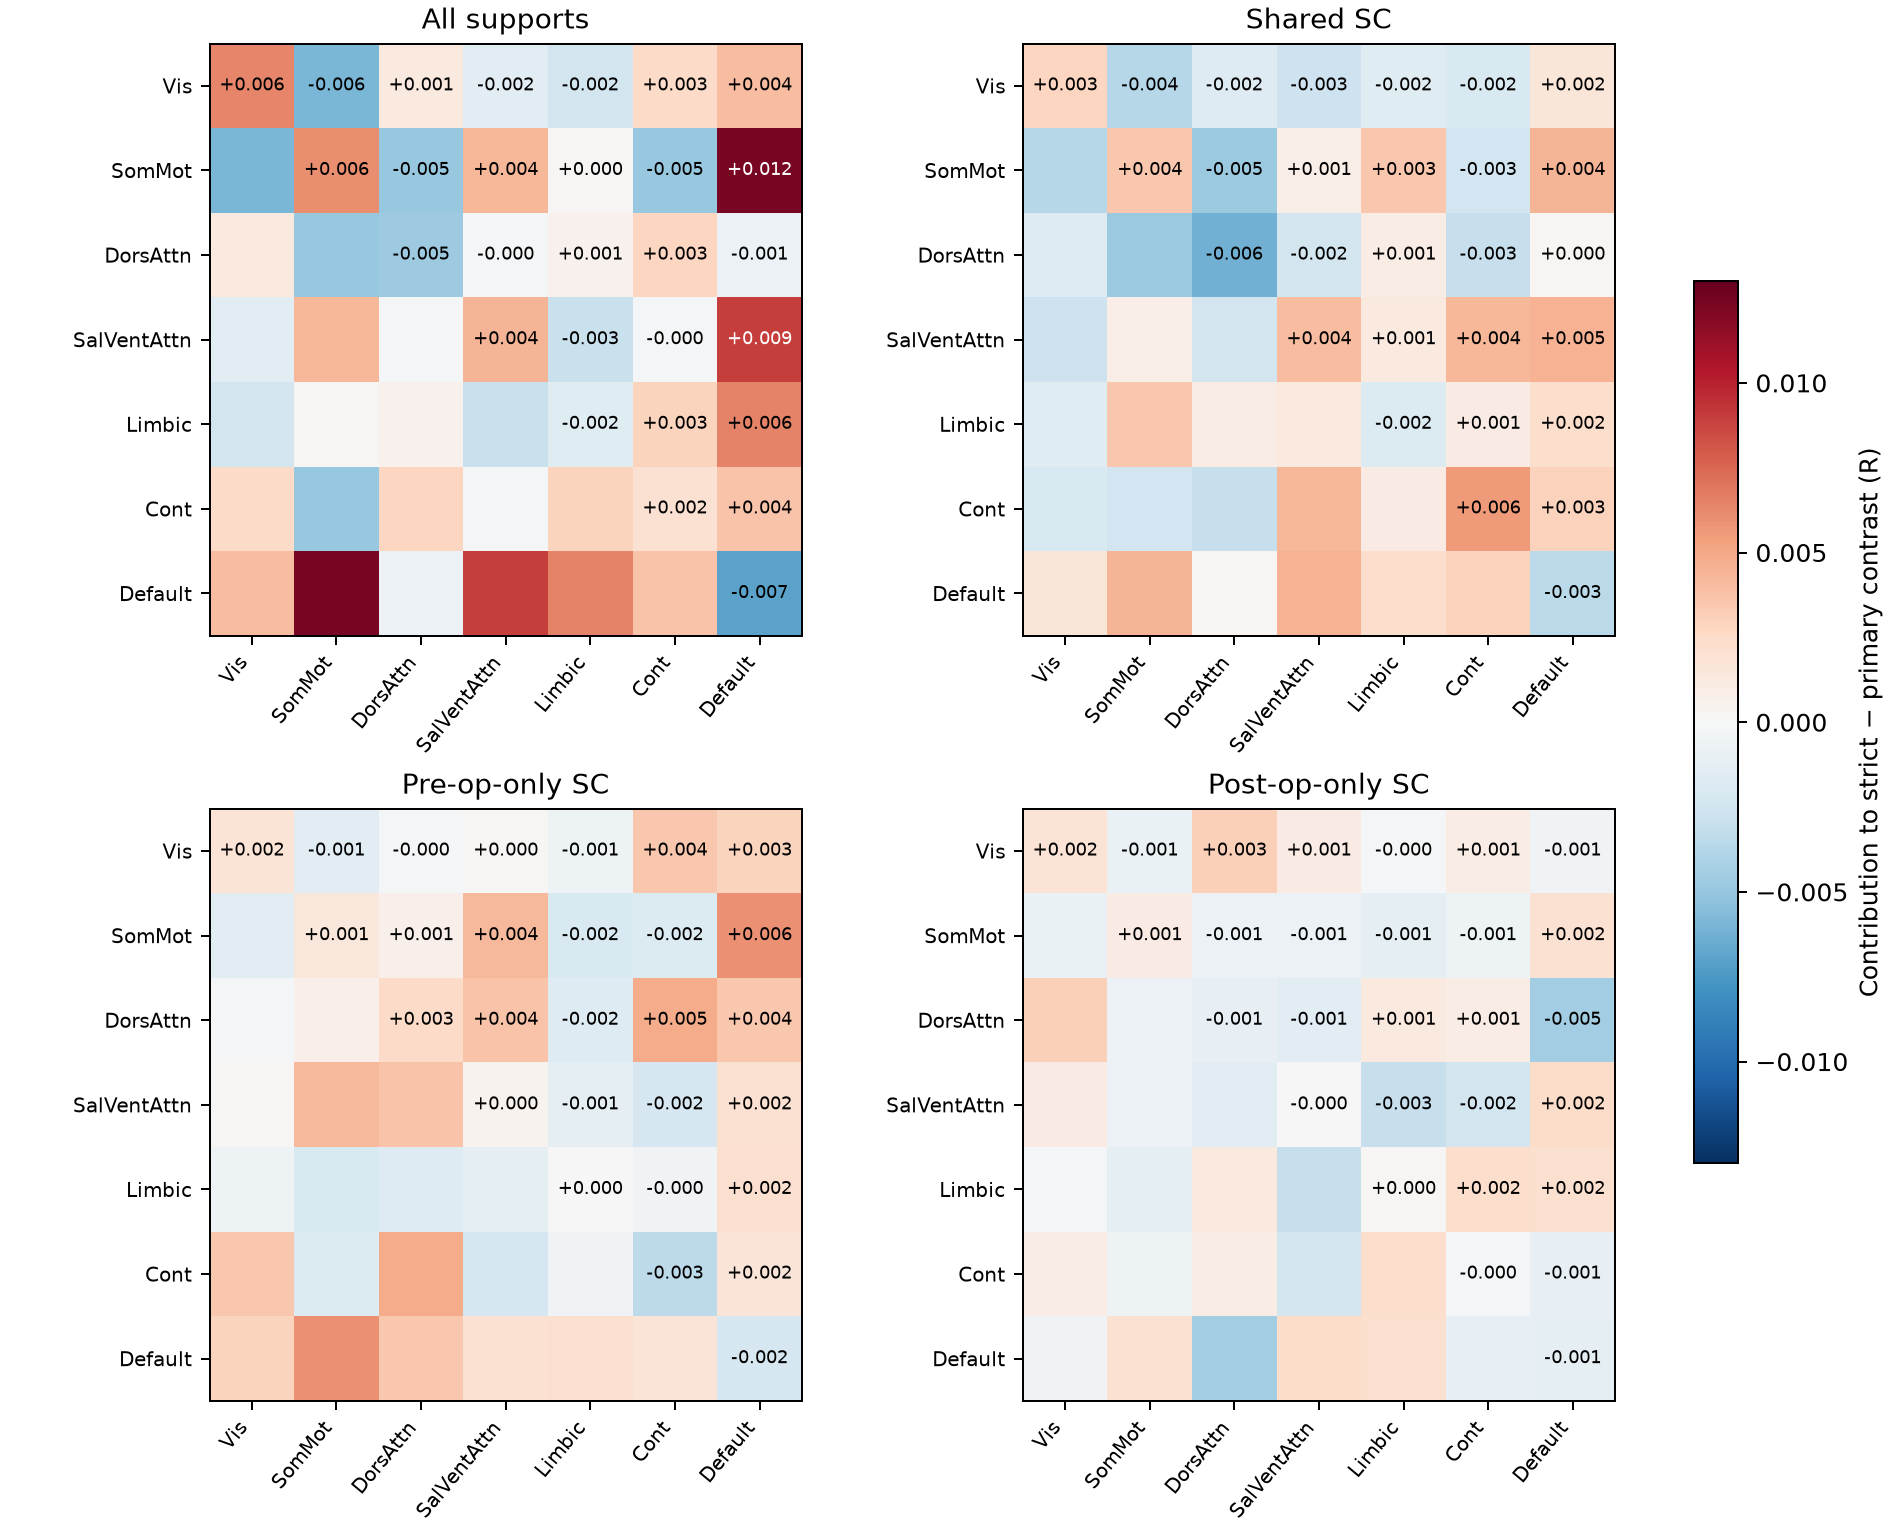

In [5]:
pairs=pd.read_csv(OUT/"network_pairs.csv")
display(pairs.sort_values("reversal_shift",ascending=False)[["pair","edges","shared_shift","pre_only_shift","post_only_shift","reversal_shift","shift_per_edge"]])
display(Image(filename=str(RESULTS/"figures/edge_driver_networks.png")))

### Inspect the individual edges
The largest positive term is edge **21–42**, LH_DorsAttn_Post_6 ↔ LH_Default_PFC_1 (pre-only, 1/0 streamlines), rₑ=+0.00277. The largest negative term is edge **16–35**, LH_DorsAttn_Post_1 ↔ LH_Cont_PFCl_1 (shared), rₑ=−0.00287. A pair can contain large terms of both signs even when its net term is small or opposite. Across all edges, positive terms sum +0.4165 and negative terms −0.3846: strong cancellation yields the modest net +0.0319.

Use source IDs/labels to inspect the full inventory. Straight lines below connect atlas centroids in pre-op T1 RAS coordinates; **they are not reconstructed tracts**. A near-footprint endpoint does not show that a tract crosses tumour or cavity. The endpoint≤10-mm group contributes −0.01463, versus +0.04649 when both endpoints are farther away; this sensitivity is not confined to lesion-near atlas endpoints.

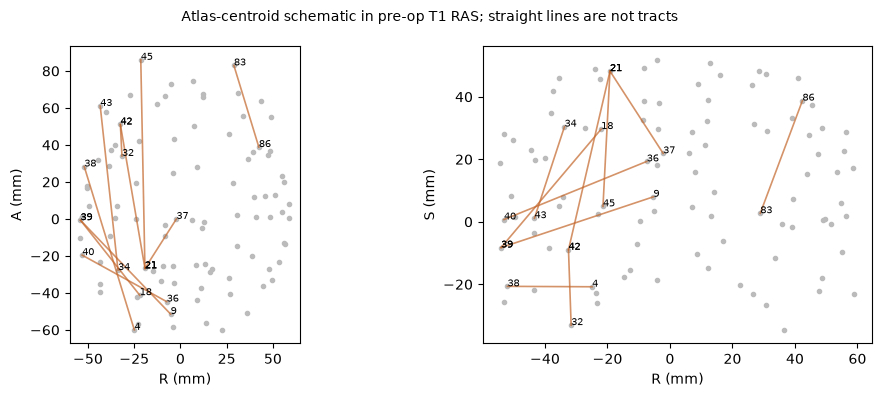

,node_i,node_j,label_i,label_j,support_group,sc_pre,sc_post,reversal_shift,leave_one_primary_delta,leave_one_pca_delta
646,21,42,7Networks_LH_DorsAttn_Post_6,7Networks_LH_Default_PFC_1,pre_only,1,0,0.002773,-0.019707,0.009463
996,34,43,7Networks_LH_Cont_Par_1,7Networks_LH_Default_PFC_2,shared,1,9,0.002583,-0.019391,0.010068
643,21,37,7Networks_LH_DorsAttn_Post_6,7Networks_LH_Cont_Cing_1,shared,1,6,0.002418,-0.019442,0.010023
936,32,42,7Networks_LH_Limbic_TempPole_1,7Networks_LH_Default_PFC_1,shared,27,45,0.002400,-0.019339,0.010209
562,18,39,7Networks_LH_DorsAttn_Post_3,7Networks_LH_Default_Temp_2,shared,1,20,0.002266,-0.018161,0.011534
126,4,38,7Networks_LH_Vis_4,7Networks_LH_Default_Temp_1,shared,37,37,0.002123,-0.020310,0.009366
1912,83,86,7Networks_RH_Cont_PFCl_1,7Networks_RH_Cont_PFCl_4,shared,32,26,0.002092,-0.020926,0.008870
246,9,39,7Networks_LH_Vis_9,7Networks_LH_Default_Temp_2,pre_only,1,0,0.002048,-0.020021,0.009925
648,21,45,7Networks_LH_DorsAttn_Post_6,7Networks_LH_Default_PFC_4,pre_only,1,0,0.002022,-0.020202,0.009668
1040,36,40,7Networks_LH_Cont_pCun_1,7Networks_LH_Default_Par_1,pre_only,1,0,0.001970,-0.019910,0.010183


interactive(children=(Dropdown(description='support', options=('all', 'shared', 'pre_only', 'post_only'), valu…

<function __main__.edge_browser(support='all', pair='all', top=10, direction='positive')>

In [6]:
def edge_browser(support="all",pair="all",top=10,direction="positive"):
    fig,chosen=show_edges(support,pair,top,direction);plt.show();plt.close(fig)
    display(chosen[["node_i","node_j","label_i","label_j","support_group","sc_pre","sc_post","reversal_shift","leave_one_primary_delta","leave_one_pca_delta"]])
widgets.interact(edge_browser,support=widgets.Dropdown(options=["all"]+GROUPS,value="all"),pair=widgets.Dropdown(options=["all"]+sorted(pairs.pair.tolist()),value="all"),top=widgets.IntSlider(min=1,max=30,value=10,continuous_update=False),direction=widgets.Dropdown(options=["positive","negative"],value="positive"))

## Deleting edges changes every remaining rank
All **2003** single-edge deletions preserve the original negative-primary/positive-strict contrast. No individual edge is necessary for the sign reversal. Removing the top ten positive rₑ edges jointly makes strict Δ slightly negative (−0.00109), but this set was chosen from these same observations: it is a descriptive stress test, not validation of ten causal pathways.

Deleting **pre-only** edges leaves primary/strict Δ=−0.0137/+0.0017; deleting **post-only** edges gives −0.0472/−0.0282. This differs from the additive accounting: the post-only direct R term is small, yet its removal changes the remaining rank context. Removing both session-specific groups gives the shared-only negative contrasts.

Removing **all Default-incident edges** makes both contrasts positive (+0.0367/+0.0393), while removing **SalVentAttn-, Limbic-, or Cont-incident edges** makes both negative. Thus no unique support class, network or edge can be labelled the biological cause. Incident sets overlap, and their deletion effects are not additive.

,kind,removed,union_edges_removed,primary_delta,pca_delta,reversal_shift
0,baseline,none,0,-0.020720,0.011144,0.031865
1,support,shared,1071,-0.060888,-0.010688,0.050201
2,support,pre_only,444,-0.013705,0.001742,0.015447
3,support,post_only,488,-0.047177,-0.028187,0.018990
4,support,all_session_specific,932,-0.040161,-0.037590,0.002572
33,network_incident,Vis,445,-0.019131,0.017036,0.036167
34,network_incident,SomMot,511,-0.021541,0.013059,0.034600
35,network_incident,DorsAttn,578,-0.038348,0.021223,0.059570
36,network_incident,SalVentAttn,475,-0.036852,-0.015825,0.021027
37,network_incident,Limbic,247,-0.034214,-0.005608,0.028606


,removed,primary_delta,pca_delta,reversal_shift
40,positive_1,-0.019707,0.009463,0.029170
41,positive_5,-0.013126,0.006706,0.019832
42,positive_10,-0.010830,-0.001086,0.009744
43,positive_25,-0.000687,-0.017004,-0.016317
44,positive_50,0.007984,-0.045861,-0.053845
45,positive_100,0.032342,-0.084556,-0.116898
46,negative_1,-0.021831,0.012996,0.034828
47,negative_5,-0.026984,0.018056,0.045040
48,negative_10,-0.029454,0.027021,0.056475
49,negative_25,-0.037988,0.046222,0.084210


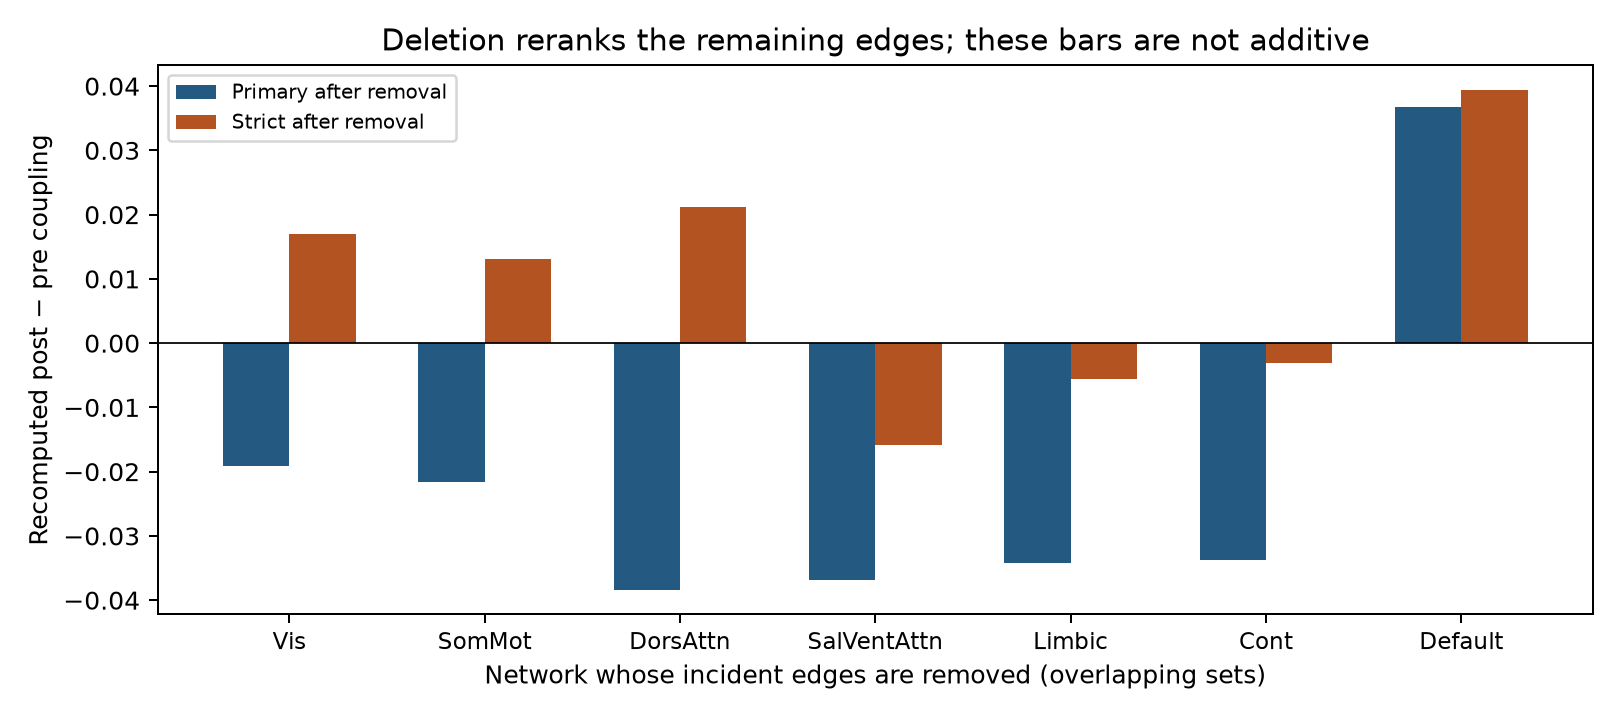

In [7]:
deletions=pd.read_csv(OUT/"deletions.csv")
display(deletions[deletions.kind.isin(["baseline","support","network_incident"])][["kind","removed","union_edges_removed","primary_delta","pca_delta","reversal_shift"]])
display(deletions[deletions.kind=="top_edges"][["removed","primary_delta","pca_delta","reversal_shift"]])
display(Image(filename=str(RESULTS/"figures/edge_driver_deletions.png")))

## Replay the same motion/duration-matched samples
All 6×200 previous draws are reproduced using exactly their saved masks, both frozen and fully refitted nuisance models. Per-edge contrasts sum to each prior global matched Δ. Support/pair **means** sum to the mean total; marginal medians/quantiles generally do not. Ranges remain conditional sampling spreads, not confidence intervals or probabilities of a surgery effect.

For strict pools, the pre-only full-refit term is fixed at **−0.03102**, because all 68 pre-op frames are selected on every draw. Changing FD-only matching to FD+run-half matching shifts the **shared-edge mean term from −0.03272 to −0.01395**, and the post-only mean term from +0.05032 to +0.05560. The total mean changes from −0.01343 to +0.01063. Most of that design difference comes from shared edges, rather than changing the fixed pre-only term.

A separate `refit_effect` is Δ(refitted)−Δ(frozen) on the **same selected frames**; it is not the original strict-minus-primary full-sample R. The pre-only effect is +0.01782 in all strict designs, while shared effects change from −0.00489 under FD matching to +0.01224 with half matching. Across network-pair means, the largest positive half-versus-FD design shift is **Cont–SomMot +0.00408**, whereas that pair opposes the original full-sample R. Driver localization therefore depends on the question and selected data, not only the atlas.

,group,edges,mean_contribution,median_contribution,q025,q975,positive_fraction
609,pre_only,444,-0.031024,-0.031024,-0.031024,-0.031024,0.0
608,shared,1071,-0.013954,-0.014529,-0.032961,0.005469,0.1
610,post_only,488,0.055604,0.055845,0.042353,0.068998,1.0


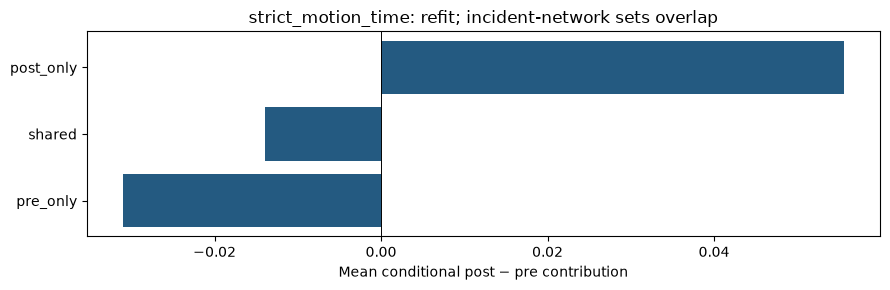

interactive(children=(Dropdown(description='protocol', index=5, options=('primary_duration', 'primary_motion',…

<function __main__.matched_components(protocol='strict_motion_time', mode='refit', partition='support')>

In [8]:
matched_groups=pd.read_csv(OUT/"matched_group_summary.csv")
replay=pd.read_csv(OUT/"matched_reproduction.csv")
print("Largest discrepancy from previous matched Δ:",replay.previous_delta_error.abs().max())
def matched_components(protocol="strict_motion_time",mode="refit",partition="support"):
    g=matched_groups[(matched_groups.protocol==protocol)&(matched_groups["mode"]==mode)&(matched_groups.partition==partition)].sort_values("mean_contribution")
    display(g[["group","edges","mean_contribution","median_contribution","q025","q975","positive_fraction"]])
    fig,ax=plt.subplots(figsize=(9,max(3,.22*len(g))))
    ax.barh(g.group,g.mean_contribution,color="#245a81");ax.axvline(0,color="black",lw=.7)
    ax.set_xlabel("Mean conditional post − pre contribution" if mode!="refit_effect" else "Mean same-frame refitting contribution")
    ax.set_title(f"{protocol}: {mode}; incident-network sets overlap");plt.tight_layout();plt.show();plt.close(fig)
widgets.interact(matched_components,protocol=widgets.Dropdown(options=matched_groups.protocol.unique().tolist(),value="strict_motion_time"),mode=widgets.Dropdown(options=["frozen","refit","refit_effect"],value="refit"),partition=widgets.Dropdown(options=["support","network_pair","network_incident"],value="support"))

### Follow one edge through the refitting sequence
The edge inventory retains measured FC even where SC is absent, but absent edges make no contribution to that session's coupling. Inspect Pearson FC alongside the edge's *global-rank* contribution. A large FC change is not necessarily a large coupling contribution, and an additive rₑ is not the same as its leave-one-out deletion effect.

node_i                                               16
node_j                                               35
label_i                    7Networks_LH_DorsAttn_Post_1
label_j                        7Networks_LH_Cont_PFCl_1
support_group                                    shared
sc_pre                                               50
sc_post                                              62
reversal_shift                                -0.002873
leave_one_primary_delta                       -0.021831
leave_one_pca_delta                            0.012996
Name: 0, dtype: object

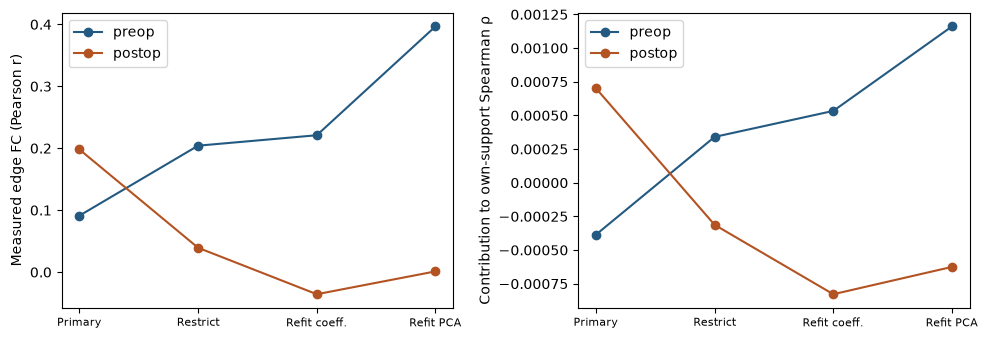

interactive(children=(IntSlider(value=1, continuous_update=False, description='rank', max=2003, min=1), Output…

<function __main__.inspect_edge(rank=1)>

In [9]:
ranked=edges.reindex(edges.reversal_shift.abs().sort_values(ascending=False).index).reset_index(drop=True)
def inspect_edge(rank=1):
    r=ranked.iloc[rank-1]
    display(r[["node_i","node_j","label_i","label_j","support_group","sc_pre","sc_post","reversal_shift","leave_one_primary_delta","leave_one_pca_delta"]])
    stages=["primary","restriction","coefficients","pca"]
    fig,axs=plt.subplots(1,2,figsize=(10,3.5))
    for session,color in [("preop","#245a81"),("postop","#b35322")]:
        axs[0].plot(range(4),[r[f"{session}_{s}_fc"] for s in stages],"o-",color=color,label=session)
        axs[1].plot(range(4),[r[f"{session}_{s}_contribution"] for s in stages],"o-",color=color,label=session)
    for ax in axs:ax.set_xticks(range(4),["Primary","Restrict","Refit coeff.","Refit PCA"],fontsize=8);ax.legend()
    axs[0].set_ylabel("Measured edge FC (Pearson r)");axs[1].set_ylabel("Contribution to own-support Spearman ρ");plt.tight_layout();plt.show();plt.close(fig)
widgets.interact(inspect_edge,rank=widgets.IntSlider(min=1,max=len(ranked),value=1,continuous_update=False))

## Reproducibility and interpretation
`uv run python scripts/investigate_edge_drivers.py` regenerates the exact decomposition, complete 2003-edge CSV inventory, every single-edge deletion, support/network stress tests and matched replay. No imaging/FSL stage runs. All masks, counts, atlas IDs, measured FC, rank terms and source hashes are bundled; `matched_edge_contrasts.npz` stores draw×edge arrays in `edges.csv` order. See `config/COUPLING_EDGE_DRIVERS.md`.

This analysis localizes a **methodological sensitivity**. Pre-only edges dominate the original signed rank accounting, Default cross-network pairs provide the largest positive totals, and opposing terms are substantial. Reranked deletion and matched controls change that account. None establishes tract loss, neural recovery/decline, or a cognitive/QoL mechanism. This original edge accounting remains a seed-160 sensitivity. New common-consensus edge/network accounting is in `results/primary_sc`; all clinical source fields remain unchanged.

**Exercises:** explain why a small post-only additive R term can coexist with a large deletion effect; reconstruct R from support and pair sums; compare a top individual edge with its pair's aggregate sign; compare shared-edge pooled contributions with shared-only Spearman; identify which matched terms remain fixed because pre-op strict samples do not change. Continue in notebook [09](09_structural_edge_reliability.ipynb) for repeated tractography and count-threshold controls. What repeated imaging and physiological evidence would be needed before assigning a biological interpretation?